# TS5 – Estimación espectral y ancho de banda de señales reales

## Introducción

En este trabajo se realizará el análisis espectral de diferentes señales reales mediante la estimación de su **densidad espectral de potencia (PSD)**. Las señales analizadas corresponden a registros de distinta naturaleza: una señal de **electrocardiograma (ECG)**, una señal de **pletismografía (PPG)** y diferentes registros de **audio**, incluyendo voz y silbidos.

Para estimar la PSD se utilizará el **método de Welch**, uno de los métodos de estimación espectral estudiados en clase. Este método divide la señal en segmentos, calcula la estimación espectral de cada uno de ellos y posteriormente los promedia, permitiendo obtener una estimación más estable de la densidad espectral de potencia.

A partir de las PSD obtenidas se realizará también una estimación del **ancho de banda** de cada señal. Para ello se utilizará un criterio basado en la proporción de potencia contenida en el espectro. En el caso de las señales ECG y PPG se considerará un comportamiento **pasabajo**, mientras que para las señales de audio se considerará un comportamiento **pasabanda**.

Finalmente, se compararán los resultados obtenidos para las diferentes señales mediante una tabla resumen y se analizarán las principales diferencias observadas entre sus características espectrales.

## 1. Librerías y carga de las señales

En primer lugar, se importan las librerías necesarias para el procesamiento y representación de las señales. A continuación, se cargan los registros de ECG, PPG y audio proporcionados para la realización del trabajo.

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import scipy.signal as sig

In [59]:
import os

if os.path.basename(os.getcwd()) != 'TS5':
    os.chdir('TS5')

In [60]:
# Frecuencia de muestreo del ECG
fs_ecg = 1000  # Hz

# Carga del archivo .mat
mat_struct = sio.loadmat('ECG_TP4.mat')

# Extracción de la señal ECG
ecg = mat_struct['ecg_lead'].squeeze()

print('Número de muestras del ECG:', len(ecg))
print('Frecuencia de muestreo:', fs_ecg, 'Hz')
print('Duración:', len(ecg) / fs_ecg, 's')

Número de muestras del ECG: 1129116
Frecuencia de muestreo: 1000 Hz
Duración: 1129.116 s


In [61]:
# Frecuencia de muestreo del PPG
fs_ppg = 400  # Hz

# Carga del archivo CSV
ppg = np.genfromtxt('PPG.csv', delimiter=',', skip_header=1)

# Nos aseguramos de trabajar con un vector
ppg = ppg.squeeze()

print('Número de muestras del PPG:', len(ppg))
print('Frecuencia de muestreo:', fs_ppg, 'Hz')
print('Duración:', len(ppg) / fs_ppg, 's')

Número de muestras del PPG: 45319
Frecuencia de muestreo: 400 Hz
Duración: 113.2975 s


In [62]:
# Carga de los registros de audio
fs_voz, audio_voz = sio.wavfile.read('prueba psd.wav')
fs_silbido, audio_silbido = sio.wavfile.read('silbido.wav')
fs_cucaracha, audio_cucaracha = sio.wavfile.read('la cucaracha.wav')

# Nos aseguramos de trabajar con vectores
audio_voz = audio_voz.squeeze()
audio_silbido = audio_silbido.squeeze()
audio_cucaracha = audio_cucaracha.squeeze()

print('VOZ')
print('Frecuencia de muestreo:', fs_voz, 'Hz')
print('Número de muestras:', len(audio_voz))
print('Duración:', len(audio_voz) / fs_voz, 's')

print('\nSILBIDO')
print('Frecuencia de muestreo:', fs_silbido, 'Hz')
print('Número de muestras:', len(audio_silbido))
print('Duración:', len(audio_silbido) / fs_silbido, 's')

print('\nLA CUCARACHA')
print('Frecuencia de muestreo:', fs_cucaracha, 'Hz')
print('Número de muestras:', len(audio_cucaracha))
print('Duración:', len(audio_cucaracha) / fs_cucaracha, 's')

VOZ
Frecuencia de muestreo: 48000 Hz
Número de muestras: 144000
Duración: 3.0 s

SILBIDO
Frecuencia de muestreo: 48000 Hz
Número de muestras: 144000
Duración: 3.0 s

LA CUCARACHA
Frecuencia de muestreo: 48000 Hz
Número de muestras: 144000
Duración: 3.0 s


## 2. Visualización de las señales en el dominio temporal

Antes de realizar la estimación espectral, se representan las señales en el dominio temporal para observar sus principales características y comprobar que los registros se han cargado correctamente.

Para cada señal se construye el vector temporal a partir de su frecuencia de muestreo y del número de muestras disponibles.

In [63]:
# Vectores de tiempo
t_ecg = np.arange(len(ecg)) / fs_ecg
t_ppg = np.arange(len(ppg)) / fs_ppg

t_voz = np.arange(len(audio_voz)) / fs_voz
t_silbido = np.arange(len(audio_silbido)) / fs_silbido
t_cucaracha = np.arange(len(audio_cucaracha)) / fs_cucaracha

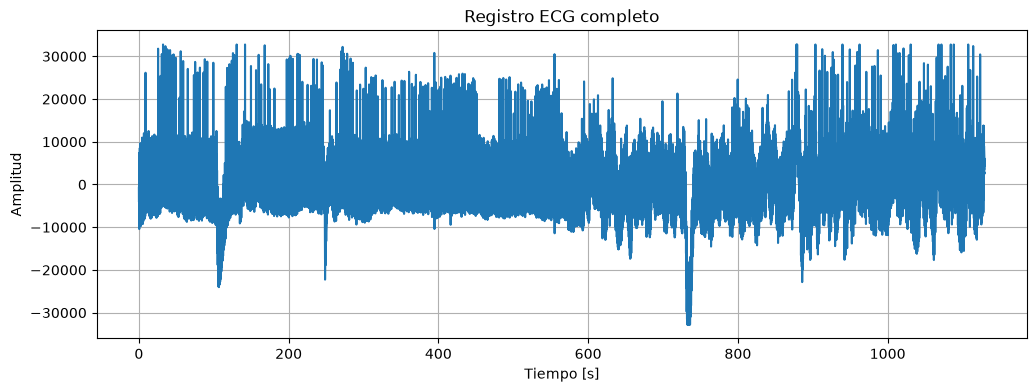

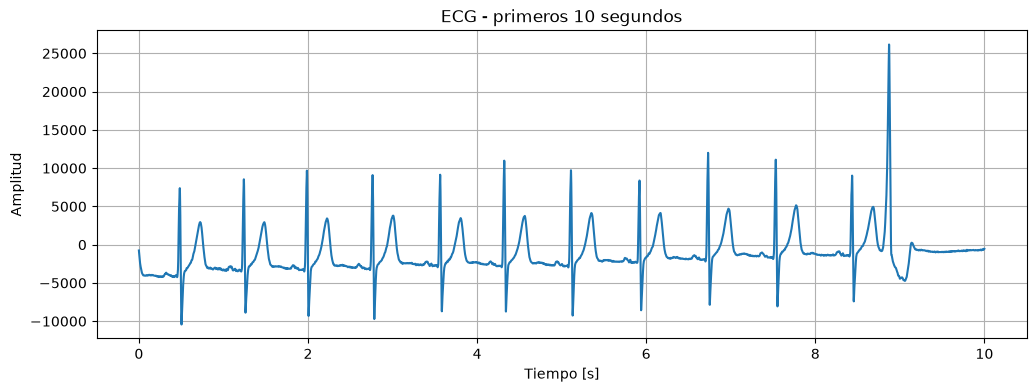

In [64]:
# ECG completo
plt.figure(figsize=(12, 4))
plt.plot(t_ecg, ecg)
plt.title('Registro ECG completo')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

# Fragmento de 10 segundos
plt.figure(figsize=(12, 4))
plt.plot(t_ecg[:10*fs_ecg], ecg[:10*fs_ecg])
plt.title('ECG - primeros 10 segundos')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

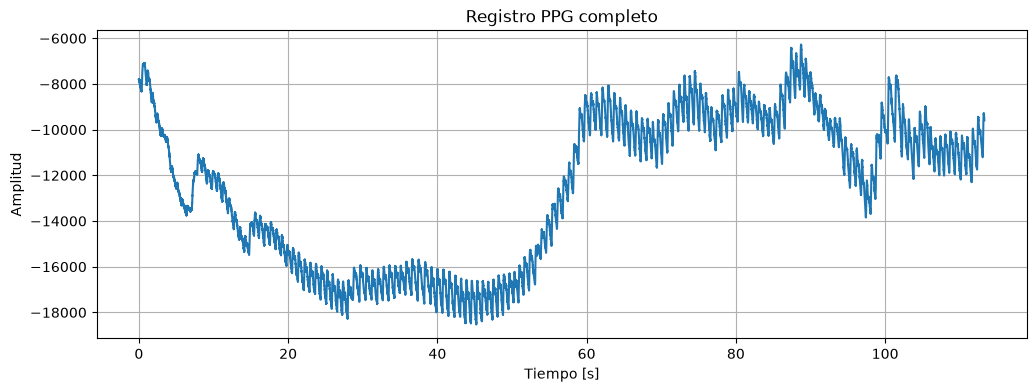

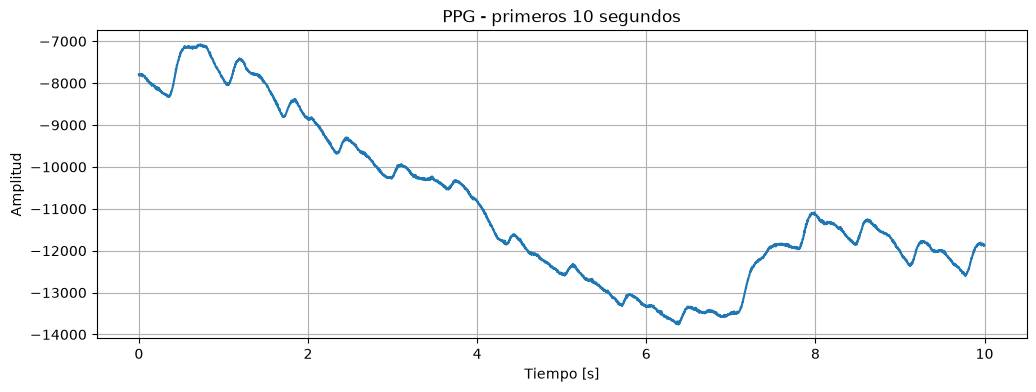

In [65]:
# PPG completo
plt.figure(figsize=(12, 4))
plt.plot(t_ppg, ppg)
plt.title('Registro PPG completo')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

# Fragmento de 10 segundos
plt.figure(figsize=(12, 4))
plt.plot(t_ppg[:10*fs_ppg], ppg[:10*fs_ppg])
plt.title('PPG - primeros 10 segundos')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

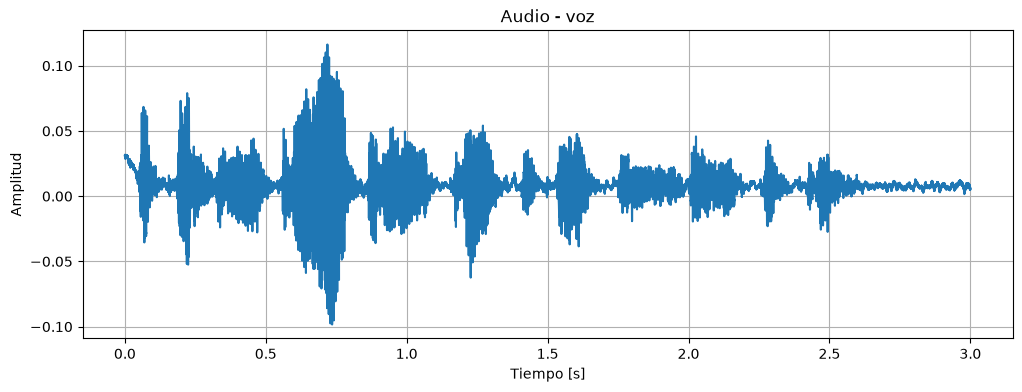

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(t_voz, audio_voz)
plt.title('Audio - voz')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t_silbido, audio_silbido)
plt.title('Audio - silbido')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t_cucaracha, audio_cucaracha)
plt.title('Audio - La Cucaracha')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

## 3. Estimación de la densidad espectral de potencia (PSD)

La densidad espectral de potencia (PSD) permite analizar cómo se distribuye la potencia de una señal en función de la frecuencia.

Para su estimación se utilizará el **método de Welch**. Este método divide la señal en segmentos parcialmente solapados, aplica una ventana a cada segmento y calcula sus periodogramas, que posteriormente son promediados. De esta forma se reduce la variabilidad de la estimación espectral respecto al uso de un único periodograma.

Antes de realizar la estimación se elimina el valor medio de cada señal, evitando que una componente continua (DC) elevada domine la representación espectral.

Las PSD se representarán en escala logarítmica (dB) para facilitar la visualización de componentes con niveles de potencia muy diferentes.

In [ ]:
# Eliminación del valor medio de cada señal
ecg_0 = ecg - np.mean(ecg)
ppg_0 = ppg - np.mean(ppg)

audio_voz_0 = audio_voz - np.mean(audio_voz)
audio_silbido_0 = audio_silbido - np.mean(audio_silbido)
audio_cucaracha_0 = audio_cucaracha - np.mean(audio_cucaracha)

In [ ]:
# PSD del ECG mediante Welch
nperseg_ecg = 4 * fs_ecg

f_ecg, psd_ecg = sig.welch(
    ecg_0,
    fs=fs_ecg,
    window='hann',
    nperseg=nperseg_ecg,
    noverlap=nperseg_ecg//2
)

plt.figure(figsize=(12, 4))
plt.plot(f_ecg, 10*np.log10(psd_ecg + 1e-20))
plt.title('PSD del ECG - Método de Welch')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]')
plt.grid()
plt.xlim(0, 100)
plt.show()

In [ ]:
# PSD del PPG mediante Welch
nperseg_ppg = 4 * fs_ppg

f_ppg, psd_ppg = sig.welch(
    ppg_0,
    fs=fs_ppg,
    window='hann',
    nperseg=nperseg_ppg,
    noverlap=nperseg_ppg//2
)

plt.figure(figsize=(12, 4))
plt.plot(f_ppg, 10*np.log10(psd_ppg + 1e-20))
plt.title('PSD del PPG - Método de Welch')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]')
plt.grid()
plt.xlim(0, 20)
plt.show()

### 3.2. PSD de las señales de audio

Para los registros de audio se utiliza también el método de Welch. Debido a su mayor frecuencia de muestreo, se emplean segmentos de 4096 muestras con un solapamiento del 50 %.

Los registros de audio se consideran señales pasabanda, por lo que posteriormente se determinarán tanto una frecuencia inferior como una frecuencia superior para estimar su ancho de banda.

In [ ]:
# Parámetros para Welch en las señales de audio
nperseg_audio = 4096
noverlap_audio = nperseg_audio // 2

# PSD de la voz
f_voz, psd_voz = sig.welch(
    audio_voz_0,
    fs=fs_voz,
    window='hann',
    nperseg=nperseg_audio,
    noverlap=noverlap_audio
)

# PSD del silbido
f_silbido, psd_silbido = sig.welch(
    audio_silbido_0,
    fs=fs_silbido,
    window='hann',
    nperseg=nperseg_audio,
    noverlap=noverlap_audio
)

# PSD de La Cucaracha
f_cucaracha, psd_cucaracha = sig.welch(
    audio_cucaracha_0,
    fs=fs_cucaracha,
    window='hann',
    nperseg=nperseg_audio,
    noverlap=noverlap_audio
)

In [ ]:
# PSD de la voz
plt.figure(figsize=(12, 4))
plt.plot(f_voz, 10*np.log10(psd_voz + 1e-20))
plt.title('PSD del audio de voz - Método de Welch')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]')
plt.xlim(0, 10000)
plt.grid()
plt.show()

# PSD del silbido
plt.figure(figsize=(12, 4))
plt.plot(f_silbido, 10*np.log10(psd_silbido + 1e-20))
plt.title('PSD del silbido - Método de Welch')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]')
plt.xlim(0, 10000)
plt.grid()
plt.show()

# PSD de La Cucaracha
plt.figure(figsize=(12, 4))
plt.plot(f_cucaracha, 10*np.log10(psd_cucaracha + 1e-20))
plt.title('PSD de La Cucaracha - Método de Welch')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]')
plt.xlim(0, 10000)
plt.grid()
plt.show()

### Observaciones

En las señales ECG y PPG se observa que la mayor parte de la potencia se concentra en las frecuencias bajas, disminuyendo progresivamente al aumentar la frecuencia. Este comportamiento es consistente con su consideración como señales pasabajo.

En el ECG también se observa una componente espectral alrededor de 50 Hz, que podría estar asociada a interferencia de la red eléctrica presente durante la adquisición.

En el PPG la concentración de potencia en las frecuencias más bajas es especialmente marcada, debido tanto a la componente pulsátil de la señal como a las variaciones lentas de su línea de base.

## 4. Estimación del ancho de banda

El ancho de banda de cada señal se estimará utilizando un criterio basado en la proporción de potencia contenida en su espectro.

Dado que las señales analizadas presentan una PSD continua y no existe una frecuencia de corte perfectamente definida, se considera como banda útil aquella que contiene una proporción elevada de la potencia total de la señal. En este trabajo se utilizará un criterio del **99 % de la potencia**.

Para las señales **ECG y PPG**, consideradas pasabajo, se determinará una frecuencia superior $f_B$ tal que el intervalo comprendido entre 0 Hz y $f_B$ contenga el 99 % de la potencia espectral.

Para las señales de **audio**, consideradas pasabanda, se determinarán dos frecuencias, $f_L$ y $f_H$. Se descartará un 0.5 % de la potencia en cada extremo del espectro, de manera que el intervalo comprendido entre ambas frecuencias contenga el 99 % de la potencia total.

De esta forma, el ancho de banda se calcula como:

- **Señales pasabajo:** $B = f_B$
- **Señales pasabanda:** $B = f_H - f_L$

La potencia espectral acumulada se obtiene integrando la PSD respecto a la frecuencia. Como la PSD se encuentra evaluada en frecuencias discretas igualmente espaciadas, esta integral se aproxima mediante una suma de los valores de la PSD multiplicados por la resolución frecuencial $\Delta f$:

$$
P_{\mathrm{acum}}(f_k) \approx \sum_{i=0}^{k} S_{xx}(f_i)\,\Delta f
$$

Posteriormente, la potencia espectral acumulada se normaliza respecto a la potencia espectral total:

$$
P_{\mathrm{norm}}(f_k) =
\frac{P_{\mathrm{acum}}(f_k)}
{P_{\mathrm{acum}}(f_{\mathrm{max}})}
$$

De esta forma, $P_{\mathrm{norm}}(f_k)$ representa la proporción de potencia espectral contenida desde 0 Hz hasta la frecuencia $f_k$, y permite determinar las frecuencias límite correspondientes al criterio del 99 %.

In [ ]:
def ancho_banda_pasobajo(f, psd, porcentaje=0.99):
    """
    Estima el ancho de banda de una señal pasabajo a partir
    de la potencia acumulada de su PSD.
    """
    
    # Resolución frecuencial
    df = f[1] - f[0]
    
    # Potencia acumulada
    potencia_acumulada = np.cumsum(psd) * df
    
    # Normalización respecto a la potencia total
    potencia_normalizada = potencia_acumulada / potencia_acumulada[-1]
    
    # Primera frecuencia que alcanza el porcentaje indicado
    indice = np.where(potencia_normalizada >= porcentaje)[0][0]
    fB = f[indice]
    
    return fB, potencia_normalizada

In [ ]:
# Estimación del ancho de banda del ECG y PPG
fB_ecg, pot_acum_ecg = ancho_banda_pasobajo(f_ecg, psd_ecg)
fB_ppg, pot_acum_ppg = ancho_banda_pasobajo(f_ppg, psd_ppg)

print(f'Frecuencia límite ECG: {fB_ecg:.2f} Hz')
print(f'Ancho de banda ECG: {fB_ecg:.2f} Hz')

print()

print(f'Frecuencia límite PPG: {fB_ppg:.2f} Hz')
print(f'Ancho de banda PPG: {fB_ppg:.2f} Hz')

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(f_ecg, pot_acum_ecg * 100)
plt.axhline(99, linestyle='--', label='99 %')
plt.axvline(fB_ecg, linestyle='--', label=f'fB = {fB_ecg:.2f} Hz')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Potencia espectral acumulada [%]')
plt.title('Potencia espectral acumulada - ECG')
plt.xlim(0, 100)
plt.ylim(0, 101)
plt.grid()
plt.legend()
plt.show()


plt.figure(figsize=(10, 4))
plt.plot(f_ppg, pot_acum_ppg * 100)
plt.axhline(99, linestyle='--', label='99 %')
plt.axvline(fB_ppg, linestyle='--', label=f'fB = {fB_ppg:.2f} Hz')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Potencia espectral acumulada [%]')
plt.title('Potencia espectral acumulada - PPG')
plt.xlim(0, 20)
plt.ylim(0, 101)
plt.grid()
plt.legend()
plt.show()

### Resultados para las señales pasabajo

Aplicando el criterio del 99 % de la potencia espectral acumulada, se obtiene una frecuencia límite de **31.00 Hz para el ECG** y de **4.75 Hz para el PPG**.

Por tanto, al considerar ambas señales como pasabajo, sus anchos de banda estimados son:

- **ECG:** \(B = 31.00\) Hz
- **PPG:** \(B = 4.75\) Hz

En el ECG, aunque en la PSD se observa una componente alrededor de 50 Hz, el 99 % de la potencia espectral se alcanza antes de dicha frecuencia, por lo que esta componente no determina el ancho de banda estimado mediante el criterio utilizado.

El PPG presenta un ancho de banda considerablemente menor, lo que concuerda con la fuerte concentración de potencia observada en las frecuencias más bajas.

In [ ]:
def ancho_banda_pasobanda(f, psd, porcentaje=0.99):
    """
    Estima el ancho de banda de una señal pasabanda a partir
    de la potencia acumulada de su PSD.
    """
    
    # Resolución frecuencial
    df = f[1] - f[0]
    
    # Potencia acumulada
    potencia_acumulada = np.cumsum(psd) * df
    
    # Normalización respecto a la potencia total
    potencia_normalizada = potencia_acumulada / potencia_acumulada[-1]
    
    # Potencia que dejamos fuera en cada extremo
    margen = (1 - porcentaje) / 2
    
    # Frecuencia inferior
    indice_L = np.where(potencia_normalizada >= margen)[0][0]
    
    # Frecuencia superior
    indice_H = np.where(potencia_normalizada >= 1 - margen)[0][0]
    
    fL = f[indice_L]
    fH = f[indice_H]
    
    # Ancho de banda
    B = fH - fL
    
    return fL, fH, B, potencia_normalizada

In [ ]:
# Estimación del ancho de banda de los registros de audio

fL_voz, fH_voz, B_voz, pot_acum_voz = ancho_banda_pasobanda(
    f_voz, psd_voz
)

fL_silbido, fH_silbido, B_silbido, pot_acum_silbido = ancho_banda_pasobanda(
    f_silbido, psd_silbido
)

fL_cucaracha, fH_cucaracha, B_cucaracha, pot_acum_cucaracha = ancho_banda_pasobanda(
    f_cucaracha, psd_cucaracha
)


print('VOZ')
print(f'Frecuencia inferior: {fL_voz:.2f} Hz')
print(f'Frecuencia superior: {fH_voz:.2f} Hz')
print(f'Ancho de banda: {B_voz:.2f} Hz')

print('\nSILBIDO')
print(f'Frecuencia inferior: {fL_silbido:.2f} Hz')
print(f'Frecuencia superior: {fH_silbido:.2f} Hz')
print(f'Ancho de banda: {B_silbido:.2f} Hz')

print('\nLA CUCARACHA')
print(f'Frecuencia inferior: {fL_cucaracha:.2f} Hz')
print(f'Frecuencia superior: {fH_cucaracha:.2f} Hz')
print(f'Ancho de banda: {B_cucaracha:.2f} Hz')

In [ ]:
# Potencia acumulada - Voz
plt.figure(figsize=(10, 4))
plt.plot(f_voz, pot_acum_voz * 100)
plt.axhline(0.5, linestyle='--', label='0.5 %')
plt.axhline(99.5, linestyle='--', label='99.5 %')
plt.axvline(fL_voz, linestyle='--', label=f'fL = {fL_voz:.2f} Hz')
plt.axvline(fH_voz, linestyle='--', label=f'fH = {fH_voz:.2f} Hz')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Potencia espectral acumulada [%]')
plt.title('Potencia espectral acumulada - Voz')
plt.xlim(0, 10000)
plt.ylim(0, 101)
plt.grid()
plt.legend()
plt.show()


# Potencia acumulada - Silbido
plt.figure(figsize=(10, 4))
plt.plot(f_silbido, pot_acum_silbido * 100)
plt.axhline(0.5, linestyle='--', label='0.5 %')
plt.axhline(99.5, linestyle='--', label='99.5 %')
plt.axvline(fL_silbido, linestyle='--', label=f'fL = {fL_silbido:.2f} Hz')
plt.axvline(fH_silbido, linestyle='--', label=f'fH = {fH_silbido:.2f} Hz')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Potencia espectral acumulada [%]')
plt.title('Potencia espectral acumulada - Silbido')
plt.xlim(0, 10000)
plt.ylim(0, 101)
plt.grid()
plt.legend()
plt.show()


# Potencia acumulada - La Cucaracha
plt.figure(figsize=(10, 4))
plt.plot(f_cucaracha, pot_acum_cucaracha * 100)
plt.axhline(0.5, linestyle='--', label='0.5 %')
plt.axhline(99.5, linestyle='--', label='99.5 %')
plt.axvline(fL_cucaracha, linestyle='--', label=f'fL = {fL_cucaracha:.2f} Hz')
plt.axvline(fH_cucaracha, linestyle='--', label=f'fH = {fH_cucaracha:.2f} Hz')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Potencia espectral acumulada [%]')
plt.title('Potencia espectral acumulada - La Cucaracha')
plt.xlim(0, 10000)
plt.ylim(0, 101)
plt.grid()
plt.legend()
plt.show()

## 5. Comparación de los anchos de banda estimados

A partir del criterio del 99 % de la potencia espectral se obtuvieron las frecuencias límite y los anchos de banda de cada uno de los registros analizados.

En las señales consideradas pasabajo, ECG y PPG, la frecuencia inferior se considera igual a 0 Hz. En los registros de audio, considerados pasabanda, se obtuvieron una frecuencia inferior y una frecuencia superior, calculándose el ancho de banda como la diferencia entre ambas.

In [ ]:
# Tabla comparativa de resultados

print(f'{"Señal":<15} {"Tipo":<12} {"fL [Hz]":>12} {"fH [Hz]":>12} {"B [Hz]":>12}')
print('-' * 67)

print(f'{"ECG":<15} {"Pasabajo":<12} {0:>12.2f} {fB_ecg:>12.2f} {fB_ecg:>12.2f}')
print(f'{"PPG":<15} {"Pasabajo":<12} {0:>12.2f} {fB_ppg:>12.2f} {fB_ppg:>12.2f}')
print(f'{"Voz":<15} {"Pasabanda":<12} {fL_voz:>12.2f} {fH_voz:>12.2f} {B_voz:>12.2f}')
print(f'{"Silbido":<15} {"Pasabanda":<12} {fL_silbido:>12.2f} {fH_silbido:>12.2f} {B_silbido:>12.2f}')
print(f'{"La Cucaracha":<15} {"Pasabanda":<12} {fL_cucaracha:>12.2f} {fH_cucaracha:>12.2f} {B_cucaracha:>12.2f}')

## 6. Interpretación de los resultados

Los resultados obtenidos muestran diferencias claras entre las señales biomédicas y los registros de audio.

El **ECG** presenta un ancho de banda estimado de **31.00 Hz**. La mayor parte de su potencia se concentra en bajas frecuencias, por lo que su comportamiento puede considerarse pasabajo. Aunque en su PSD aparece una componente alrededor de 50 Hz, el 99 % de la potencia espectral se alcanza antes de dicha frecuencia.

El **PPG** presenta el menor ancho de banda de todas las señales analizadas, con un valor de **4.75 Hz**. Esto concuerda con la fuerte concentración de potencia observada en las frecuencias más bajas de su espectro.

En los registros de audio se observa un comportamiento diferente. La **voz** presenta una banda estimada entre **23.44 Hz y 3925.78 Hz**, correspondiente a un ancho de banda de **3902.34 Hz**. Su potencia se encuentra distribuida en un intervalo frecuencial considerablemente mayor que en las señales biomédicas.

El registro de **silbido** presenta una banda comprendida aproximadamente entre **2636.72 Hz y 6691.41 Hz**, con un ancho de banda de **4054.69 Hz**. A diferencia de la voz, prácticamente no presenta potencia significativa en las frecuencias más bajas.

Finalmente, en el registro de **La Cucaracha** la mayor parte de la potencia se concentra entre **984.38 Hz y 2015.62 Hz**, obteniéndose un ancho de banda de **1031.25 Hz**. La concentración de potencia en una región relativamente estrecha del espectro es consistente con el carácter tonal del silbido utilizado para reproducir la melodía.

Por tanto, el criterio basado en contener el 99 % de la potencia permite establecer de forma cuantitativa y reproducible una banda útil para cada señal, evitando seleccionar las frecuencias límite únicamente mediante inspección visual del espectro.

## 7. Bonus: análisis de una señal electromiográfica (EMG)

Como señal adicional se ha seleccionado una señal de **electromiografía superficial de alta densidad (HD-sEMG)**. Esta técnica permite registrar, mediante electrodos situados sobre la superficie de la piel, las variaciones de potencial asociadas a la actividad eléctrica muscular.

La señal utilizada procede del dataset abierto *Open Access Dataset and Toolbox of High-Density Surface Electromyogram Recordings (Hyser)*, disponible en **PhysioNet**. Este conjunto de datos contiene registros HD-sEMG obtenidos de diferentes sujetos durante distintas tareas motoras de la mano.

Para este análisis se ha seleccionado un registro perteneciente al conjunto de contracciones voluntarias máximas (**MVC, Maximal Voluntary Contraction**). Concretamente, se utiliza el registro del **sujeto 01, sesión 1**, durante una tarea de **extensión del dedo 1**, identificado como:

`mvc_raw_finger1_extension`

Se utiliza la versión **raw** del registro, es decir, la señal original antes del preprocesamiento disponible en el propio dataset.

El registro contiene **256 canales de HD-sEMG**, adquiridos con una frecuencia de muestreo de **2048 Hz**. Cada canal contiene **20480 muestras**, correspondientes a **10 segundos de adquisición**, y los datos se encuentran almacenados digitalmente con una resolución de **16 bits**.

Para realizar el análisis se seleccionará el primer canal del registro, identificado como `ED-8-8`. Sobre este canal se repetirá el procedimiento utilizado con las señales anteriores: representación en el dominio temporal, estimación de la **densidad espectral de potencia (PSD)** mediante el método de **Welch** y estimación del **ancho de banda** mediante el criterio del 99 % de la potencia espectral acumulada.

**Fuente:** Jiang, X., Dai, C., Liu, X., & Fan, J. (2023). *Open Access Dataset and Toolbox of High-Density Surface Electromyogram Recordings (version 2.0.0).* PhysioNet. DOI: 10.13026/hxan-pe94.

### 7.1 Carga del registro EMG

En primer lugar, se carga el archivo correspondiente al registro EMG seleccionado. Los datos se encuentran almacenados en formato digital de 16 bits y contienen simultáneamente las muestras correspondientes a los 256 canales.

Una vez cargados, los datos se reorganizan en una matriz en la que cada columna corresponde a uno de los canales del registro.

In [ ]:
# Parámetros del registro EMG
fs_emg = 2048
n_canales = 256
n_muestras = 20480

# Lectura de los datos digitales
datos_emg = np.fromfile('mvc_raw_finger1_extension.dat', dtype='<i2')

# Separar los 256 canales
datos_emg = datos_emg.reshape(n_muestras, n_canales)

print('Dimensiones del registro:', datos_emg.shape)

### 7.2 Selección y visualización del canal EMG

Para realizar el análisis se selecciona el primer canal del registro (`ED-8-8`). Los valores almacenados en el archivo corresponden a valores digitales, por lo que se convierten a unidades físicas utilizando la ganancia y el valor de referencia indicados en la cabecera del registro.

Una vez convertido el canal, se construye su vector temporal y se representa la señal completa para observar su comportamiento durante los 10 segundos de adquisición.

In [ ]:
# Selección del primer canal (ED-8-8)
emg_digital = datos_emg[:, 0]

# Parámetros obtenidos de la cabecera
ganancia_emg = 33562.1484
baseline_emg = -2296

# Conversión de valores digitales a unidades físicas
emg = (emg_digital - baseline_emg) / ganancia_emg

# Vector temporal
t_emg = np.arange(len(emg)) / fs_emg

print(f'Número de muestras: {len(emg)}')
print(f'Frecuencia de muestreo: {fs_emg} Hz')
print(f'Duración: {len(emg)/fs_emg:.2f} s')

# Representación temporal
plt.figure(figsize=(12, 4))
plt.plot(t_emg, emg)
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud [V]')
plt.title('Señal EMG - Canal ED-8-8')
plt.grid()
plt.show()

### 7.3 Estimación de la densidad espectral de potencia del EMG

A continuación, se estima la densidad espectral de potencia del canal EMG seleccionado mediante el método de Welch, manteniendo el mismo procedimiento utilizado para las señales anteriores.

Antes de calcular la PSD se elimina el valor medio de la señal. Para la estimación se utilizan segmentos de 4096 muestras con un solapamiento del 50 %. Dado que la frecuencia de muestreo es de 2048 Hz, esta elección proporciona una resolución frecuencial de 0.5 Hz.

La PSD se representa en escala logarítmica para facilitar la observación de la distribución de potencia en frecuencia.

In [ ]:
# Eliminar el valor medio
emg_0 = emg - np.mean(emg)

# Parámetros de Welch
nperseg_emg = 4096

f_emg, psd_emg = sig.welch(
    emg_0,
    fs=fs_emg,
    window='hann',
    nperseg=nperseg_emg,
    noverlap=nperseg_emg//2
)

print(f'Resolución frecuencial: {fs_emg/nperseg_emg:.2f} Hz')

# Representación de la PSD
plt.figure(figsize=(10, 5))
plt.plot(f_emg, 10*np.log10(psd_emg + 1e-20))
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]')
plt.title('PSD de la señal EMG - Método de Welch')
plt.xlim(0, 600)
plt.grid()
plt.show()

### 7.4 Estimación del ancho de banda del EMG

Para estimar el ancho de banda de la señal EMG se utiliza el mismo criterio basado en la potencia espectral acumulada empleado anteriormente.

Se considera como banda útil el intervalo que contiene el **99 % de la potencia espectral**, descartando un 0.5 % de la potencia en cada extremo del espectro. De esta forma se obtienen una frecuencia inferior $f_L$ y una frecuencia superior $f_H$, y el ancho de banda se calcula como:

$$
B = f_H - f_L
$$

In [ ]:
# Estimación del ancho de banda del EMG
fL_emg, fH_emg, B_emg, pot_acum_emg = ancho_banda_pasobanda(
    f_emg, psd_emg
)

print('EMG')
print(f'Frecuencia inferior: {fL_emg:.2f} Hz')
print(f'Frecuencia superior: {fH_emg:.2f} Hz')
print(f'Ancho de banda: {B_emg:.2f} Hz')

In [ ]:
# Representación de la potencia espectral acumulada

plt.figure(figsize=(10, 5))

plt.plot(f_emg, pot_acum_emg * 100)

plt.axhline(0.5, linestyle='--', label='0.5 %')
plt.axhline(99.5, linestyle='--', label='99.5 %')

plt.axvline(fL_emg, linestyle='--',
            label=f'fL = {fL_emg:.2f} Hz')

plt.axvline(fH_emg, linestyle='--',
            label=f'fH = {fH_emg:.2f} Hz')

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Potencia espectral acumulada [%]')
plt.title('Potencia espectral acumulada - EMG')
plt.xlim(0, 600)
plt.ylim(0, 100)
plt.grid()
plt.legend()
plt.show()

### 7.5 Resultados e interpretación

Aplicando el criterio del 99 % de la potencia espectral, se obtiene para el canal EMG analizado una frecuencia inferior de **13.00 Hz** y una frecuencia superior de **476.50 Hz**. Por tanto, el ancho de banda estimado es:

$$
B = 476.50 - 13.00 = 463.50 \ \text{Hz}
$$

La PSD muestra que la potencia de la señal no se concentra en una única frecuencia, sino que se distribuye sobre una banda relativamente amplia. La mayor concentración de potencia se encuentra en las frecuencias más bajas de esta banda y disminuye progresivamente al aumentar la frecuencia.

Este comportamiento es claramente diferente al observado en las señales ECG y PPG, cuyos anchos de banda estimados fueron considerablemente menores. El análisis del EMG muestra, por tanto, que distintas señales biomédicas pueden presentar características espectrales muy diferentes dependiendo del fenómeno fisiológico registrado.

En el dominio temporal también se distinguen intervalos de mayor y menor actividad muscular, observándose un aumento considerable de la amplitud de la señal durante los periodos de actividad.

### 7.6 Comparación con las señales anteriores

Para finalizar el análisis, se incorpora la señal EMG a la tabla comparativa obtenida anteriormente. De esta forma, pueden compararse sus características espectrales con las del ECG, PPG y las señales de audio analizadas en los apartados anteriores.

In [ ]:
print(f'{"Señal":<15} {"Tipo":<12} {"fL [Hz]":>12} {"fH [Hz]":>12} {"B [Hz]":>12}')
print('-' * 67)

print(f'{"ECG":<15} {"Pasabajo":<12} {0:>12.2f} {fB_ecg:>12.2f} {fB_ecg:>12.2f}')
print(f'{"PPG":<15} {"Pasabajo":<12} {0:>12.2f} {fB_ppg:>12.2f} {fB_ppg:>12.2f}')
print(f'{"Voz":<15} {"Pasabanda":<12} {fL_voz:>12.2f} {fH_voz:>12.2f} {B_voz:>12.2f}')
print(f'{"Silbido":<15} {"Pasabanda":<12} {fL_silbido:>12.2f} {fH_silbido:>12.2f} {B_silbido:>12.2f}')
print(f'{"La Cucaracha":<15} {"Pasabanda":<12} {fL_cucaracha:>12.2f} {fH_cucaracha:>12.2f} {B_cucaracha:>12.2f}')
print(f'{"EMG":<15} {"Pasabanda":<12} {fL_emg:>12.2f} {fH_emg:>12.2f} {B_emg:>12.2f}')

## 8. Conclusiones

En este trabajo se realizó la estimación espectral de diferentes señales reales mediante el **método de Welch**, permitiendo estudiar cómo se distribuye su potencia en función de la frecuencia.

Para estimar el ancho de banda se utilizó un criterio común basado en contener el **99 % de la potencia espectral**. En las señales consideradas pasabajo, ECG y PPG, se determinó una única frecuencia límite superior, mientras que en las señales consideradas pasabanda se determinaron una frecuencia inferior y una frecuencia superior.

Los resultados muestran diferencias importantes entre los distintos tipos de señales. El **PPG** presentó el menor ancho de banda, con **4.75 Hz**, seguido del **ECG**, con **31.00 Hz**. Los registros de audio presentaron bandas considerablemente mayores y distribuidas en regiones diferentes del espectro. La voz presentó un ancho de banda de **3902.34 Hz**, el silbido de **4054.69 Hz** y el registro de La Cucaracha de **1031.25 Hz**.

Como análisis adicional se estudió una señal de **electromiografía superficial (EMG)**, obteniéndose una banda comprendida entre **13.00 Hz y 476.50 Hz**, correspondiente a un ancho de banda de **463.50 Hz**.

En conjunto, los resultados muestran que el ancho de banda depende fuertemente de la naturaleza de la señal analizada. El uso de la PSD y de un criterio basado en potencia acumulada permite caracterizar estas diferencias de forma cuantitativa y reproducible.